In [82]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [83]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Load Data

In [84]:
# ==========================================
# 1. TRANSFORMATIONS
# ==========================================

train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(
        224,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [85]:
# ==========================================
# 2. LOAD DATASETS
# ==========================================

dataset_path = './streamlit-app/dataset'

# Dataset without transformations, for obtaining labels
base_dataset = datasets.ImageFolder(root=dataset_path)

# Separate datasets with their respective transformations
train_full = datasets.ImageFolder(
    root=dataset_path,
    transform=train_transforms
)

val_full = datasets.ImageFolder(
    root=dataset_path,
    transform=val_transforms
)

In [86]:
# ==========================================
# 3. STRATIFIED TRAIN-VALIDATION SPLIT
# ==========================================

indices = list(range(len(base_dataset)))
labels = base_dataset.targets

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.25,
    stratify=labels,
    random_state=42
)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(val_full, val_indices)

In [87]:
# ==========================================
# 4. DATA LOADERS
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=2
)

In [88]:
# ==========================================
# 5. DATASET INFORMATION
# ==========================================

classes = base_dataset.classes
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']
Number of classes: 6
Training images: 1779
Validation images: 594


In [89]:
for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    print('Images and Labels on device.')
    break

Images and Labels on device.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9466565..1.7859696].


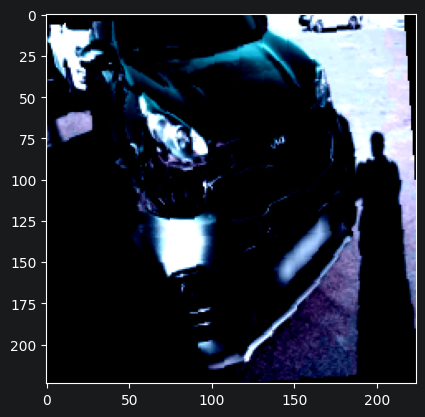

In [90]:
plt.imshow(images[15].cpu().permute(1,2,0))
plt.show()

## Model: Transfer Learning with Efficient Net V2-S (with hyperparameters updated from Optuna study)

In [91]:
def train_model(model, criterion, optimizer, train_loader, scheduler, val_loader, epochs=5):
    start = time.time()
    # Model Training:
    best_accuracy = 0.0
    scaler = torch.amp.GradScaler('cuda')

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for batch_num, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            # Zero the parameter gradients
            optimizer.zero_grad()
            # Forward pass
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            # Backward pass
            scaler.scale(loss).backward()
            # Update the weights
            scaler.step(optimizer)
            scaler.update()

            if (batch_num+1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():.2f}")

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss/len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

    # Model Evaluation:

        model.eval()
        total = 0.0
        correct = 0.0
        all_labels = []
        all_predictions = []
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                # OPTIMIZATION: Use autocast in validation too for speed/memory efficiency
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

            val_accuracy = 100 * correct / total
            avg_val_loss = val_loss / len(val_loader.dataset)
            print(f"Validation Accuracy: {val_accuracy:.2f}%")

         # METHOD 1: Check if the current validation accuracy beats the historical best
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), 'streamlit-app/assets/best_model_weights.pth')
            print(f"--> Saved new best model at epoch {epoch+1} with accuracy: {best_accuracy:.2f}%")

            best_labels = all_labels.copy()
            best_predictions = all_predictions.copy()

        scheduler.step(avg_val_loss)
    end = time.time()
    print(f'Execution time: {end - start} seconds')

    # Load the best weights back into memory before returning so the model is ready for testing/inference
    print(f"Loading best model weights from training (Best Accuracy: {best_accuracy:.2f}%)")
    model.load_state_dict(torch.load('streamlit-app/assets/best_model_weights.pth'))

    return best_labels, best_predictions

In [92]:
class CarClassifierEffNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.41):
        super().__init__()
        self.model = models.efficientnet_v2_s(weights='DEFAULT')
        # Freeze all layers except the final fully connected layer
        for param in self.model.parameters():
            param.requires_grad = False

        # Retrieve the in_features of the original classifier (which is a Sequential block)
        in_features = self.model.classifier[1].in_features
        # Unfreeze top 2 layers and fc layers
        for param in self.model.features[-2:].parameters():
            param.requires_grad = True
        # Replace the final fully connected layer
        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.model(x)

In [103]:
model = CarClassifierEffNet(num_classes=num_classes, dropout_rate=0.29).to(device)
model_eff = models.efficientnet_v2_s(weights='DEFAULT')
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW([
    {'params': model.model.features[-2:].parameters(), 'lr_bb': 8.16e-6},
    {'params': model.model.classifier.parameters(), 'lr_cl': 6.1e-4}
], weight_decay=3.49e-6)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.2)

labels, predictions = train_model(model=model, criterion=criterion, optimizer=optimizer, scheduler=scheduler, train_loader=train_loader, val_loader=val_loader, epochs=15)

Batch: 10, Epoch: 1, Loss: 1.12
Batch: 20, Epoch: 1, Loss: 1.12
Batch: 30, Epoch: 1, Loss: 0.68
Batch: 40, Epoch: 1, Loss: 0.78
Batch: 50, Epoch: 1, Loss: 0.86
Epoch [1/15], Loss: 0.9747
Validation Accuracy: 68.35%
--> Saved new best model at epoch 1 with accuracy: 68.35%
Batch: 10, Epoch: 2, Loss: 0.51
Batch: 20, Epoch: 2, Loss: 0.63
Batch: 30, Epoch: 2, Loss: 0.83
Batch: 40, Epoch: 2, Loss: 0.87
Batch: 50, Epoch: 2, Loss: 0.68
Epoch [2/15], Loss: 0.6949
Validation Accuracy: 70.20%
--> Saved new best model at epoch 2 with accuracy: 70.20%
Batch: 10, Epoch: 3, Loss: 0.23
Batch: 20, Epoch: 3, Loss: 0.23
Batch: 30, Epoch: 3, Loss: 0.36
Batch: 40, Epoch: 3, Loss: 0.54
Batch: 50, Epoch: 3, Loss: 0.31
Epoch [3/15], Loss: 0.4972
Validation Accuracy: 72.90%
--> Saved new best model at epoch 3 with accuracy: 72.90%
Batch: 10, Epoch: 4, Loss: 0.24
Batch: 20, Epoch: 4, Loss: 0.42
Batch: 30, Epoch: 4, Loss: 0.43
Batch: 40, Epoch: 4, Loss: 0.42
Batch: 50, Epoch: 4, Loss: 0.60
Epoch [4/15], Loss: 0

## Model Evaluation with Classification Report and Confusion Matrix

In [104]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.94      0.89      0.92       133
           1       0.81      0.86      0.84       102
           2       0.90      0.90      0.90       125
           3       0.89      0.76      0.82        76
           4       0.79      0.82      0.80        83
           5       0.82      0.91      0.86        75

    accuracy                           0.87       594
   macro avg       0.86      0.86      0.86       594
weighted avg       0.87      0.87      0.87       594



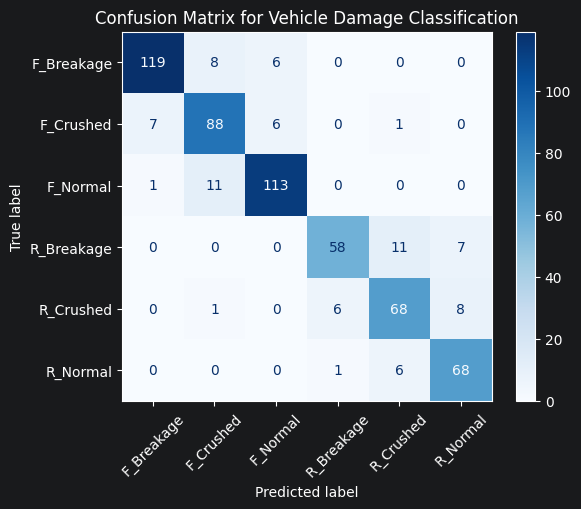

In [105]:
import numpy as np

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=classes)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()